In [149]:
# 라이브러리 호출
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# 그래프상에서 한글을 나타내기 위해 korean_mat 설치
! pip install koreanize-matplotlib
import koreanize_matplotlib

%config InlineBackend.figure_format = 'retina'

# 데이터 불러오기
df = pd.read_csv('data/movie_finished_toFDA_V9.csv')
df.head()


[notice] A new release of pip is available: 24.2 -> 24.3.1
[notice] To update, run: pip install --upgrade pip


#### 도메인
* 1. 국내의 경우, 배급사와 투자사가 일치한다 -> 배급사가 수익성을 고려하는 조건이 된다
* 2. 극장과 배급사는 영화 개봉 이후에, 흥행 여부를 고려하여 스크린수와 좌석수를 줄여 좌석판매율을 유지한다 -> 피해를 줄이려는 전략 but 흥행이 예상되는 경우 스크린수와 좌석수를 유지해 좌석판매율이  급감한다.
* 3. drop_ratio -> 추후에 추가하겠음 
* ...

#### 1. 가설
* 배급사와 투자사는 일정 수준 이상의 수익성을 기대하여 영화에 투자하게 된다. 영화에 대한 투자여부는 영화의 여러가지 요소(시나리오,장르,배우 등등)을 고려하여 결정한다. 모든 영화에 대해 천만 관객을 바라는 것은 아니지만, 투자 규모에 상응하는 수익성을 얻기를 기대한다. 

* **그렇다면 영화의 규모? 제작비?에 상응하는 지표**를 어떻게 설정할 것 인가? 혹은 수익성은 어떻게 설정할 것인가?

#### 수익성-규모 분석
* 참고 문헌: 개봉 규모와 수익성에 따른 영화의 분류와 확산 패턴 분석


* 규모: 개봉일의 좌석 수를 영화의 규모를 측정하는 대용 척도(proxy measure)로 선정하였다. -> 개봉일의 좌석수를 영화의 규모에 대한 척도로 사용한 이유

* 1. 영화의 제작비가 개봉 이전에 결정되는 요인이라는 점
* 2. 개봉일의 상용관 수 혹은 좌석의 수 경우, 많은 연구에서 영화의 배급력을 나타내는 변수
* 3. 무엇보다 제작자 및 배급사의 입장에서 제작 규모에 따라, 이 두 변수가 제작 규모를 적절히 반영할 것으로 기대할 수 있다.
* 4. 마지막으로, 상영관 수와 좌석 수 모두 영화의 규모를 반영하고 있지만, 멀티플렉스가 대부분인 한국 영화 시장의 특성을 고려할때(전체 상영관 수의 94.5%),규모가 큰 영화일수록 좌석 수가 많은 대형 상영관에 배정된다는 점과 제작비가 높은 3D 영화와 IMAX 영화의 경우 역시 해당 포맷을 위한 상영관이 모두 많은 좌석 수를 가진 점에 주목하였다

In [150]:
# 영화별 개봉일의 좌석수
df_규모_수익성 = pd.DataFrame()
df_규모_수익성['movie_title'] = df['movie_title'].unique()

# 15번째마다 행 남기기
df_규모_수익성 = pd.merge(df[::15][['좌석수', 'movie_title']], df_규모_수익성, on='movie_title', how='left').copy()

* 수익성: 일반적으로, 특정 상품이나 프로젝트 등 투자 대상의 수익성은 투자 규모에 대비한 매출로서 평가된다. 따라서 본 연구에서는 이와 같은 기준으로 사용하여 2주간의 누적 매출를 제작 규모인 개봉일의 좌석수로 나눈 값을 수익성의 척도로 정의하였다.

In [151]:
# 1. 영화별 누적 관객수를 계산
sum_viewer = df.groupby('movie_title')['매출액'].sum()

# 2. 원본 데이터프레임에 누적 관객수를 매핑하여 새로운 컬럼으로 추가
df['누적_매출액'] = df['movie_title'].map(sum_viewer)

In [152]:
df_규모_수익성 = pd.merge(df[['movie_title','누적_매출액']], df_규모_수익성, on='movie_title', how='left').copy()

# 영화별로 묶기
df_규모_수익성 = df_규모_수익성.groupby(['movie_title']).mean()

# 수익성
df_규모_수익성['수익성'] = df_규모_수익성['누적_매출액'] / df_규모_수익성['좌석수']

df_규모_수익성.rename(columns={'좌석수':'규모(좌석수)'}, inplace=True)
df_규모_수익성.drop('누적_매출액', axis=1, inplace=True)
df_규모_수익성

#### 1. 과연 규모와 수익성간의 상관관계는 어떻게 될 것인가? 
* 놀랍게도 -0.05라는 상관관계가 나온다

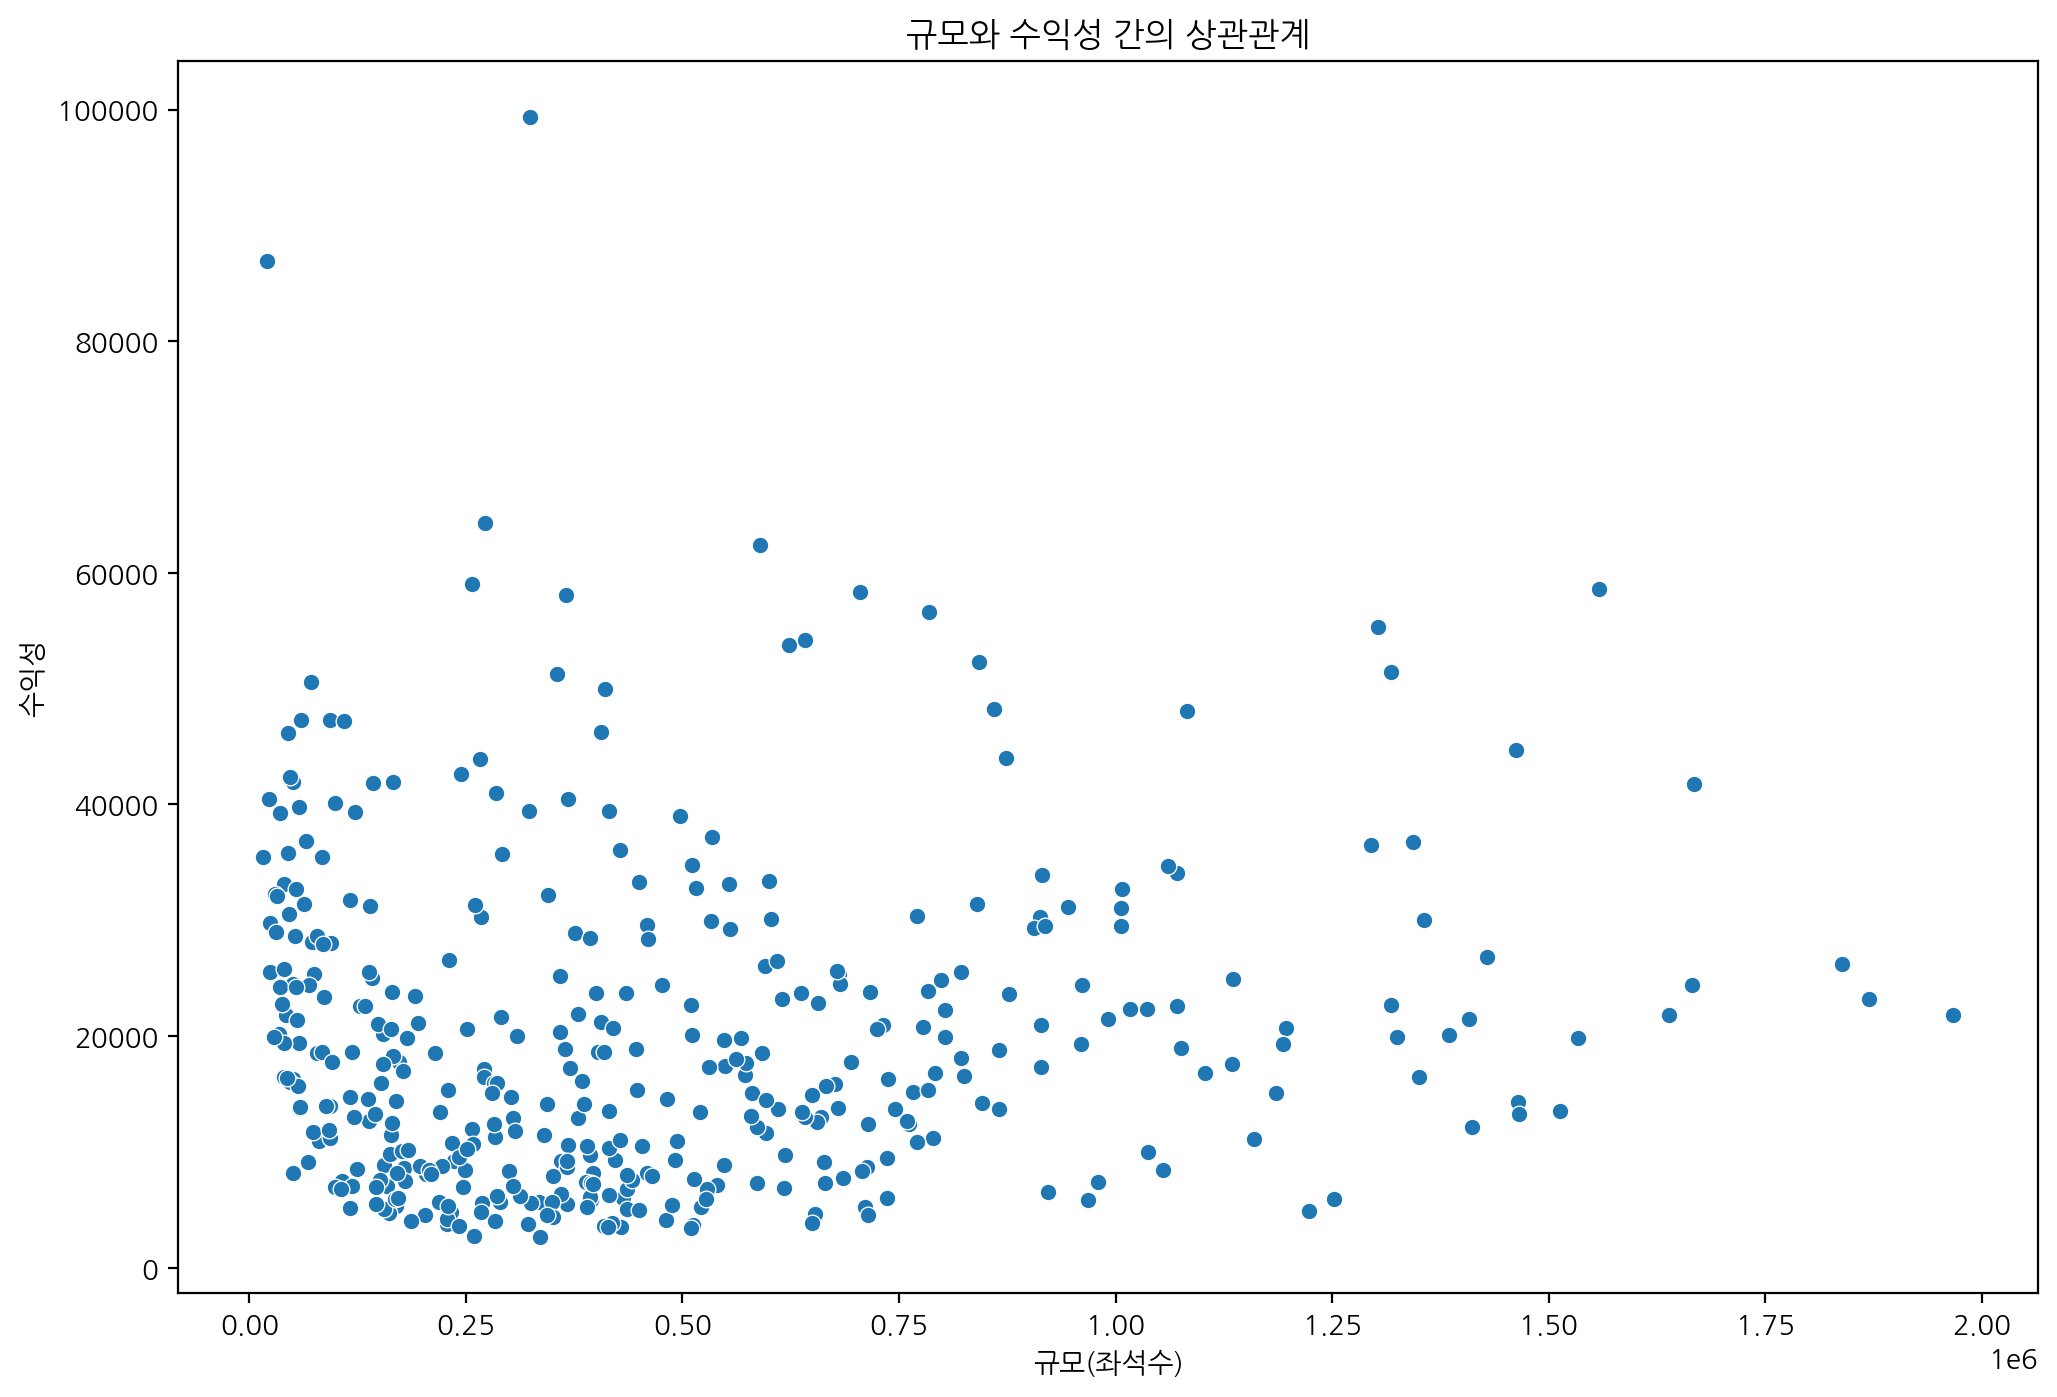

규모와 수익성 간의 상관계수: -0.05566907238298016


In [153]:
# 규모와 수익성 간의 상관관계 분석 -> 각각의 변수에 대해 log 정규화
df_규모_수익성_log = df_규모_수익성.copy()
df_규모_수익성_log['규모(좌석수)'] = np.log1p(df_규모_수익성['규모(좌석수)'])
df_규모_수익성_log['수익성'] = np.log1p(df_규모_수익성['수익성'])

plt.figure(figsize=(12, 8))
sns.scatterplot(data=df_규모_수익성, x='규모(좌석수)', y='수익성')
plt.title('규모와 수익성 간의 상관관계')
plt.show()
print('규모와 수익성 간의 상관계수:', df_규모_수익성_log['규모(좌석수)'].corr(df_규모_수익성_log['수익성']))


#### 1. 규모와 수익성간의 상관은 정말 없는 것일까?
#### 2. 수익성에 영향을 끼치는 피쳐는 무엇일까?

#### 위의 질문들을 검증하기 위해 영화(409)개를 규모와 수익성 측면에서 4개의 군집으로 클러스터링을 실시한다.

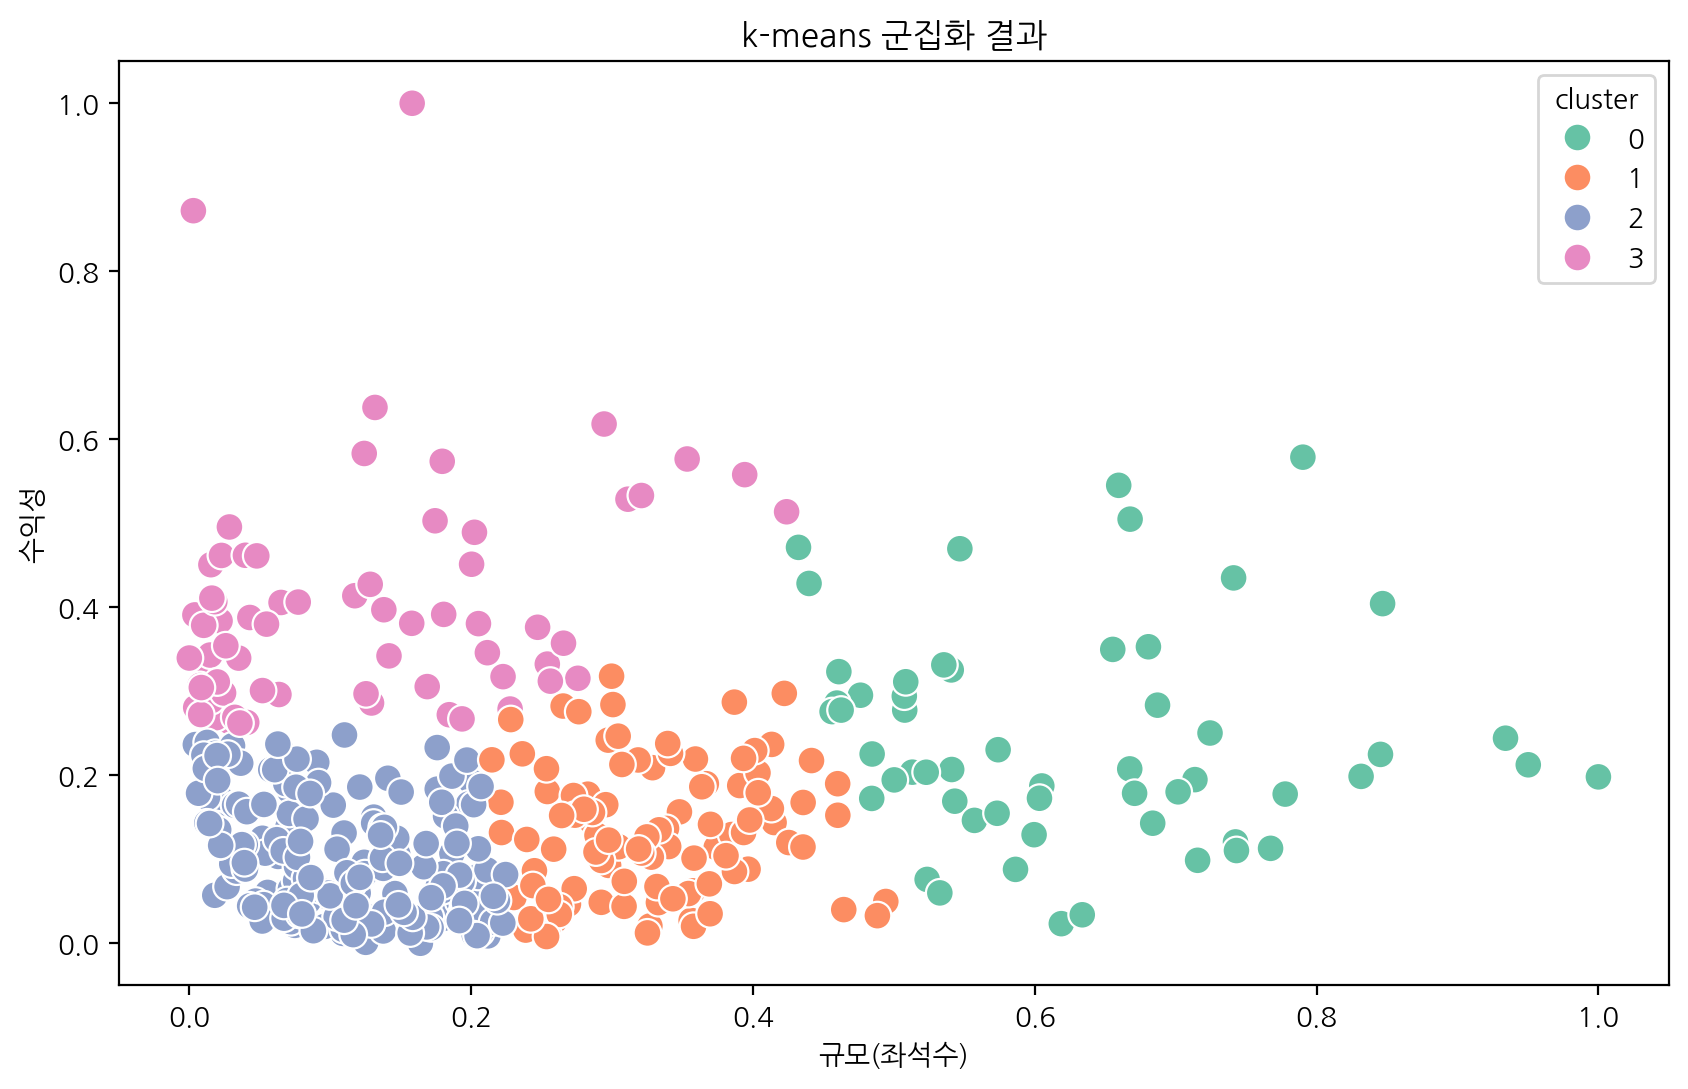

In [154]:
# min-max 정규화
df_규모_수익성['규모(좌석수)'] = (df_규모_수익성['규모(좌석수)'] - df_규모_수익성['규모(좌석수)'].min()) / (df_규모_수익성['규모(좌석수)'].max() - df_규모_수익성['규모(좌석수)'].min())
df_규모_수익성['수익성'] = (df_규모_수익성['수익성'] - df_규모_수익성['수익성'].min()) / (df_규모_수익성['수익성'].max() - df_규모_수익성['수익성'].min())

# k-means 군집화
from sklearn.cluster import KMeans

# k-means 모델 생성
kmeans = KMeans(n_clusters=4, random_state=123)

# 모델 학습
kmeans.fit(df_규모_수익성)

# 군집 결과
df_규모_수익성['cluster'] = kmeans.labels_

# 군집 시각화
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_규모_수익성, x='규모(좌석수)', y='수익성', hue='cluster', palette='Set2', s=100)
plt.title('k-means 군집화 결과')
plt.show()

In [155]:
# 군집별 통계량
df_규모_수익성.groupby('cluster').mean()

# 군집 개수
df_규모_수익성['cluster'].value_counts()

cluster
2    184
1    103
3     67
0     55
Name: count, dtype: int64

* Cluster 0:
    * 규모(좌석수)가 가장 큼 (54.1%).
    * 수익성은 두 번째로 높음 (21.6%).

* Cluster 1:
    * 규모(좌석수)가 중간 크기 (24.8%).
    * 수익성은 가장 낮음 (9.4%).

* Cluster 2:
    * 규모(좌석수)가 두 번째로 작음 (8.2%).
    * 수익성은 Cluster 1보다 높지만 상대적으로 낮음 (9.9%).

* Cluster 3:
    * 규모(좌석수)가 가장 작음 (11.5%).
    * 수익성이 가장 높음 (37.1%).

#### 군집별 회귀 분석을 통해 군집별로 수익성에 미치는 변수들의 영향력을 본다

In [156]:
df_규모_수익성_0 = df_규모_수익성[df_규모_수익성['cluster'] == 0]
df_규모_수익성_1 = df_규모_수익성[df_규모_수익성['cluster'] == 1]
df_규모_수익성_2 = df_규모_수익성[df_규모_수익성['cluster'] == 2]
df_규모_수익성_3 = df_규모_수익성[df_규모_수익성['cluster'] == 3]

#### 앞으로 회귀 분석에 사용할 칼럼 정리

In [157]:
# 독립변수

#1. 국적: nationality
#2. 장르: genre
#3. 등급: watch_grade
#4. 감독: director_power
#5. 배우: actor_power
#6. 배급사: 배급사평균최대관객수
#7. 스크린수: 스크린점유율
#8. 상영수: 상영점유율
#9. 좌석수: 좌석 점유율
#10. 포털평점: RV_score_total
#11. 소셜미디어: Total_neg_ratio,Total_neut_ratio,Total_pos_ratio

# 국적 -> 앞으로 국내 영화와 해외 영화로 분리할 예정
col_national = ['nationality'] 

# 장르 정보: -> 이후에 선형 종속 문제를 해결하기 위해 칼럼 하나를 삭제할 예정(액션)
col_genre= ['사극', 'SF', '어드벤처','범죄', '판타지', '가족', '미스터리', '스릴러', '뮤지컬',
       '코미디', '공포(호러)', '애니메이션', '드라마', '서부극(웨스턴)', '전쟁', '멜로/로맨스', '기타',
       '다큐멘터리', '공연', '성인물(에로)']

# 관람 가능 연령 타입 -> 더미 변수화
col_watch_grade = ['watch_grade']

# 영화 제작 구성원 -> 감독,배우 파워
col_power = ['director_power', 'actor_power']

# 영화 상영 정보
col_screen = ['스크린점유율','상영점유율']

# 영화 평점 정보
col_score = ['RV_score_total']

# 소셜미디어 정보 여기서 DailyTotal -> 댓글수
col_social = ['Total_neg_ratio','Total_pos_ratio','DailyTotal']


# movie_title
col_movie_title = ['movie_title']

# 입소문 칼럼



* nationality -> 국내와 해외 영화로 분류:

In [158]:
# '한국영화'라는 값이 있으면 1로, 그렇지 않으면 0으로 변경 -> 1이면 한국영화
df['nationality'] = df['nationality'].apply(lambda x: 1 if '한국' in x else 0)

In [159]:
def create_dummies(df, columns, drop_first=True): # 더미 변수 생성을 위한 함수
    return pd.get_dummies(df, columns=columns, drop_first=drop_first)

def convert_data_types(df): # True,False -> 0,1로 변환
    df.update(df.select_dtypes(include=['bool']).astype(int))
    return df

def apply_log_transformation(df, columns): # 로그 변환
    for column in columns:
        df[column] = np.log1p(df[column])
    return df

def compute_daily_averages(df, daily_columns, key='movie_title'): # 일별 데이터 집계
    daily_averages = df.groupby(key)[daily_columns].mean().reset_index()
    df = df.drop(columns=daily_columns).merge(daily_averages, on=key, how='left')
    return df.groupby(key).mean().reset_index()


# df 변수와 필요한 열 이름 리스트는 이전에 정의되어 있어야 합니다.
df_selected = df[col_movie_title + col_national + col_genre + col_watch_grade + col_power + col_screen + col_score + col_social].copy()

# 더미 변수 생성
df_selected = create_dummies(df_selected, ['nationality', 'watch_grade'])

# 데이터 타입 변환
df_selected = convert_data_types(df_selected)

# 정규화
log_columns = ['director_power', 'actor_power','DailyTotal']
df_selected = apply_log_transformation(df_selected, log_columns)

# 일별 데이터 집계
daily_columns = ['스크린점유율', '상영점유율', 'RV_score_total', 'Total_neg_ratio', 'Total_pos_ratio']
df_selected = compute_daily_averages(df_selected, daily_columns)

/var/folders/mz/tk5z94ds1qd9c1jb2p8qys9m0000gn/T/ipykernel_49485/2244469048.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[1 1 1 ... 0 0 0]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  df.update(df.select_dtypes(include=['bool']).astype(int))
/var/folders/mz/tk5z94ds1qd9c1jb2p8qys9m0000gn/T/ipykernel_49485/2244469048.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[1 1 1 ... 1 1 1]' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  df.update(df.select_dtypes(include=['bool']).astype(int))
/var/folders/mz/tk5z94ds1qd9c1jb2p8qys9m0000gn/T/ipykernel_49485/2244469048.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[0 0 0 ... 0 0 0]' has dtype incompatible with bool, please explicitly

In [160]:
pd.set_option('display.max_columns', None)
df_selected

#### 칼럼 설명
* 1. nationality -> 국적: 1,0
* 2. 장르 -> 사극 ~ 성인물 (단, 액션을 제외) 
* 3. director_power,actor_power -> 감독,배우 파워 -> 로그화
* 4. DailyTotal: 댓글수 -> 로그화
* 5. watch_grade -> 더미
* 6. 스크린점유율, 상영점유율
* 6. RV_score_total: 영화 평점
* 7. Total_neg_ratio: 부정적 댓글 비율
* 8. Total_pos_ratio: 긍정적 댓글 비율
* 9. 입소문?? -> 여기서는 영화 평균 평점을 입소문이라고 판단 ,-> 따로 입소문 지표는 넣지 않음

#### 각각의 군집에 대해 위의 데이터 프레임을 결합

In [161]:
# df_selected와 df_규모_수익성_0을 movie_title을 기준으로 병합
df_selected_0 = pd.merge(df_selected, df_규모_수익성_0, on='movie_title', how='inner')
df_selected_0.head(2)

# df_selected와 df_규모_수익성_1을 movie_title을 기준으로 병합
df_selected_1 = pd.merge(df_selected, df_규모_수익성_1, on='movie_title', how='inner')
df_selected_1.head(2)

# df_selected와 df_규모_수익성_2을 movie_title을 기준으로 병합
df_selected_2 = pd.merge(df_selected, df_규모_수익성_2, on='movie_title', how='inner')
df_selected_2.head(2)

# df_selected와 df_규모_수익성_3을 movie_title을 기준으로 병합
df_selected_3 = pd.merge(df_selected, df_규모_수익성_3, on='movie_title', how='inner')
df_selected_3.head(2)

#### 후진 제거법을 통해 변수 선택 -> 영향력 

In [162]:
import pandas as pd
import statsmodels.api as sm
import itertools
import time

# 변수 선택 과정을 수행하는 함수
def processSubset(X, y, feature_set):
    model = sm.OLS(y, sm.add_constant(X[list(feature_set)]))
    regression = model.fit()
    return {"model": regression, "AIC": regression.aic}

# 후진제거법
def backward(X, y, predictors):
    results = []
    for combo in itertools.combinations(predictors, len(predictors) - 1):
        results.append(processSubset(X, y, combo))
    models = pd.DataFrame(results)
    best_model = models.loc[models['AIC'].argmin()]
    return best_model

# 후진제거법을 사용한 전체 모델 선택
def backward_model(X, y):
    predictors = X.columns.tolist()
    Bmodels = pd.DataFrame(columns=["AIC", "model"], index = range(1, len(X.columns)))
    
    while len(predictors) > 1:
        current_model = backward(X, y, predictors)
        Bmodels.loc[len(predictors) - 1] = current_model
        predictors = current_model['model'].model.exog_names
        predictors = [p for p in predictors if p != 'const']  # 상수항 제외
        
    # 최적의 모델 추출
    best_model_index = Bmodels['AIC'].idxmin()
    best_model = Bmodels.loc[best_model_index]
    return best_model

#### 1. 군집 0
* 규모(좌석수)가 가장 큼 (54.1%).
* 수익성은 두 번째로 높음 (21.6%).

In [168]:
# 데이터 준비
X = df_selected_0.drop(['수익성', 'cluster', '규모(좌석수)', 'movie_title'], axis=1)
y = df_selected_0['수익성']

# 후진제거법을 이용한 최적 모델 탐색
final_model = backward_model(X, y)

final_model['model'].summary()

#### 2. 군집 1
* 규모(좌석수)가 중간 크기 (24.8%).
* 수익성은 가장 낮음 (9.4%).

In [170]:
# 데이터 준비
X = df_selected_1.drop(['수익성', 'cluster','규모(좌석수)' ,'movie_title'], axis=1)
y = df_selected_1['수익성']

# 후진제거법을 이용한 최적 모델 탐색
final_model = backward_model(X, y)

final_model['model'].summary()

#### 군집 2
* 규모(좌석수)가 두 번째로 작음 (8.2%).
* 수익성은 Cluster 1보다 높지만 상대적으로 낮음 (9.9%).

In [165]:
# 데이터 준비
X = df_selected_2.drop(['수익성', 'cluster', 'movie_title'], axis=1)
y = df_selected_2['수익성']

# 후진제거법을 이용한 최적 모델 탐색
final_model = backward_model(X, y)

final_model['model'].summary()

#### 군집 3
* 규모(좌석수)가 가장 작음 (11.5%).
* 수익성이 가장 높음 (37.1%).

In [166]:
# 데이터 준비
X = df_selected_3.drop(['수익성', 'cluster', 'movie_title'], axis=1)
y = df_selected_3['수익성']

# 후진제거법을 이용한 최적 모델 탐색
final_model = backward_model(X, y)

final_model['model'].summary()